# M12.5.3 — Análisis post-hoc de la condición necesaria de optimalidad de M11 (val)

Visualiza las salidas de `scripts/m12/m12_5_3_posthoc_check.py`. Protocolo: `docs/experiments/M12_5_3_posthoc_optimality_check.md`.
Solo val; cal/test no se leen; X nunca se lee. Exploratorio: no apto para seleccionar modelo.

In [1]:
import json
import sys
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'paths.py').exists())
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root, resolve_processed_artifact
from scripts.m12.m12_5_3_posthoc_check import (
    CORRECTORS, DATASET, LABELS, MIN_REGION_N, NPZ_NAME, OUT_NAME, SNR_BINS, digest, npz_to_physical)

In [2]:
cfg = json.loads((ROOT/'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
RES = DATA_ROOT/'results'/DATASET
OUT = RES/OUT_NAME
NPZ = RES/NPZ_NAME
OUT, NPZ

(PosixPath('/data/vserrano/cbc_pe_data/results/M11_final_G1_500k/M12_5_3_posthoc'),
 PosixPath('/data/vserrano/cbc_pe_data/results/M11_final_G1_500k/m11_final_G1_500k_val_predictions_embeddings.npz'))

In [3]:
read = dict(dtype={'region': str, 'heldout_env': str})
risk = pd.read_csv(OUT/'risk.csv', **read)
slopes = pd.read_csv(OUT/'slopes.csv', **read)
regions = pd.read_csv(OUT/'regions.csv', **read)
folds = pd.read_csv(OUT/'folds.csv', **read)
analysis = json.loads((OUT/'analysis.json').read_text())

In [4]:
npz_sha = digest(NPZ)
if npz_sha != analysis['npz_sha256']:
    raise ValueError(f'npz SHA256 mismatch: {npz_sha} != {analysis["npz_sha256"]}')
with np.load(NPZ, allow_pickle=False) as a:
    f = a['pred_val'].astype(np.float64)
    y = a['y_val'].astype(np.float64)
    idx = a['idx_val'].astype(np.int64)
    label_names = a['label_names'].tolist()
    y_mean = a['y_mean'].astype(np.float64)
    y_std = a['y_std'].astype(np.float64)
if label_names != LABELS:
    raise ValueError(f'Label order mismatch: {label_names}')
# Same unit handling as the script: F2 calibration curves use physical units.
y, f, npz_units = npz_to_physical(y, f, y_mean, y_std)
npz_units

'standardized'

In [5]:
# Same compact metadata as the script (it reads them inline in main()): file_group_id and
# target_network_snr indexed by idx_val. X is never read.
H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET,
                                file_name=cfg['dataset']['dataset_file'])
with h5py.File(H5, 'r') as h:
    env = h['file_group_id'][:][idx]
    snr = h['target_network_snr'][:][idx] if 'target_network_snr' in h else None
ENVS = [str(e) for e in np.unique(env)]
rows_env = {e: int((env.astype(str) == e).sum()) for e in ENVS}
if rows_env != analysis['rows_per_environment']:
    raise ValueError('Rows per environment differ from analysis.json')

## 0. Procedencia
Hashes, filas por entorno, comprobaciones superadas y disponibilidad de SNR registrados por el script.

In [6]:
script_sha_now = digest(ROOT/'scripts/m12/m12_5_3_posthoc_check.py')
print('npz           :', NPZ)
print('npz SHA256    :', analysis['npz_sha256'], '(verified)')
print('script SHA256 :', analysis['script_sha256'],
      '(matches current file)' if script_sha_now == analysis['script_sha256'] else '(DIFFERS from current file)')
print('n_rows        :', analysis['n_rows'], '| n_environments:', analysis['n_environments'])
print('SNR available :', analysis['snr']['available'], '|', analysis['snr'])
print('settings      :', analysis['settings'])
pd.Series(analysis['rows_per_environment'], name='n_rows').rename_axis('environment').to_frame()

npz           : /data/vserrano/cbc_pe_data/results/M11_final_G1_500k/m11_final_G1_500k_val_predictions_embeddings.npz
npz SHA256    : 586b95f2cb2cfaf150fbdd05760f50f47a95a555451fcb46d89492b7d00ed88b (verified)
script SHA256 : c022744039e2241c3ab1d0082e64b1d8f43d2ce8b208e883198bed897cf77c09 (matches current file)
n_rows        : 40000 | n_environments: 3
SNR available : True | {'available': True, 'source': 'HDF5 target_network_snr[idx_val]', 'n_outside_bins': 0}
settings      : {'bootstrap': 2000, 'seed': 125301, 'interval_level': 0.9958333333333333, 'margin_frac_of_m11_mse': 0.01, 'min_region_n': 200, 'c2_bins': 50, 'c3_alphas': [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0], 'c4_ks': [16, 64, 256], 'cv': 'LOEO, inner LOEO for C3/C4'}


,n_rows
environment,
7,13142
12,13432
27,13426


In [7]:
pd.Series(analysis['checks_passed'], name='check_passed').to_frame()

,check_passed
0,npz shapes
1,"label order [chirp_mass, total_mass, chi_eff]"
2,frozen G1 contract (g1_npe_contract.load_contr...
3,npz split_path is the pinned split file
4,npz y_mean/y_std equal train-only label stats ...
5,idx_val has no duplicates
6,idx_val equals val membership of split
7,all values finite
8,npz labels recognised as standardized; convert...
9,pred_val in units of y_val (|mean(pred) - mean...


## 1. Decisiones globales
ΔMSE = MSE_M11 − MSE_corrector (positivo favorece al corrector), relativo al MSE de M11, intervalo bootstrap al 99,5833 % y decisión pre-registrada.

In [8]:
tab = risk.assign(
    d_rel_pct=100 * risk.d_mean / risk.mse_m11,
    ci_lo_rel_pct=100 * risk.ci_lo / risk.mse_m11,
    ci_hi_rel_pct=100 * risk.ci_hi / risk.mse_m11,
    margin_rel_pct=100 * risk.margin / risk.mse_m11)
tab[['corrector', 'label', 'mse_m11', 'mse_corrector', 'd_mean', 'ci_lo', 'ci_hi', 'margin',
     'd_rel_pct', 'ci_lo_rel_pct', 'ci_hi_rel_pct', 'decision']]

,corrector,label,mse_m11,mse_corrector,d_mean,ci_lo,ci_hi,margin,d_rel_pct,ci_lo_rel_pct,ci_hi_rel_pct,decision
0,C1_affine,chirp_mass,33.958069,33.225962,0.732107,0.612944,0.861103,0.339581,2.155914,1.805004,2.535782,AVOIDABLE_DEMONSTRATED
1,C1_affine,total_mass,112.310568,108.850501,3.460066,2.888184,4.029585,1.123106,3.080802,2.571604,3.587894,AVOIDABLE_DEMONSTRATED
2,C1_affine,chi_eff,0.037764,0.037477,0.000287,0.000199,0.000373,0.000378,0.760025,0.528048,0.988256,NO_EVIDENCE_WITHIN_MARGIN
3,C2_binned,chirp_mass,33.958069,33.467670,0.490399,0.382855,0.597835,0.339581,1.444130,1.127434,1.760509,AVOIDABLE_DEMONSTRATED
4,C2_binned,total_mass,112.310568,109.044689,3.265879,2.705986,3.838396,1.123106,2.907900,2.409378,3.417663,AVOIDABLE_DEMONSTRATED
5,C2_binned,chi_eff,0.037764,0.037575,0.000189,0.000108,0.000268,0.000378,0.501068,0.285323,0.710020,NO_EVIDENCE_WITHIN_MARGIN
6,C3_ridge,chirp_mass,33.958069,33.006127,0.951942,0.764447,1.175739,0.339581,2.803285,2.251151,3.462326,AVOIDABLE_DEMONSTRATED
7,C3_ridge,total_mass,112.310568,107.601971,4.708597,4.005333,5.380528,1.123106,4.192479,3.566301,4.790758,AVOIDABLE_DEMONSTRATED
8,C3_ridge,chi_eff,0.037764,0.037130,0.000634,0.000463,0.000818,0.000378,1.678095,1.226067,2.166930,AVOIDABLE_DEMONSTRATED
9,C4_knn,chirp_mass,33.958069,33.066988,0.891081,0.738461,1.058357,0.339581,2.624062,2.174627,3.116658,AVOIDABLE_DEMONSTRATED


In [9]:
risk.pivot(index='corrector', columns='label', values='decision')[LABELS]

label,chirp_mass,total_mass,chi_eff
corrector,,,
C1_affine,AVOIDABLE_DEMONSTRATED,AVOIDABLE_DEMONSTRATED,NO_EVIDENCE_WITHIN_MARGIN
C2_binned,AVOIDABLE_DEMONSTRATED,AVOIDABLE_DEMONSTRATED,NO_EVIDENCE_WITHIN_MARGIN
C3_ridge,AVOIDABLE_DEMONSTRATED,AVOIDABLE_DEMONSTRATED,AVOIDABLE_DEMONSTRATED
C4_knn,AVOIDABLE_DEMONSTRATED,AVOIDABLE_DEMONSTRATED,AVOIDABLE_DEMONSTRATED


## 2. F1 — Forest plot
ΔMSE/MSE_M11 (%) con su intervalo al 99,5833 % por corrector y etiqueta; banda gris = margen ±1 %, línea en 0. Positivo favorece al corrector.

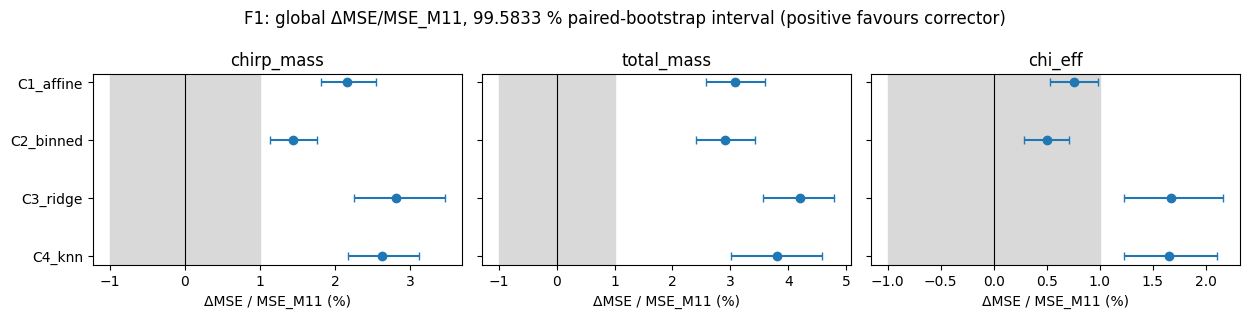

In [10]:
fig, axes = plt.subplots(1, len(LABELS), figsize=(4.2 * len(LABELS), 3.2), sharey=True)
for ax, lab in zip(axes, LABELS):
    r = tab[tab.label == lab].set_index('corrector').loc[CORRECTORS]
    pos = np.arange(len(CORRECTORS))
    ax.axvspan(-100 * 0.01, 100 * 0.01, color='0.85', zorder=0)
    ax.axvline(0, color='k', lw=0.8)
    ax.errorbar(r.d_rel_pct, pos, xerr=[r.d_rel_pct - r.ci_lo_rel_pct, r.ci_hi_rel_pct - r.d_rel_pct],
                fmt='o', capsize=3)
    ax.set_yticks(pos)
    ax.set_yticklabels(CORRECTORS)
    ax.invert_yaxis()
    ax.set_title(lab)
    ax.set_xlabel('ΔMSE / MSE_M11 (%)')
fig.suptitle('F1: global ΔMSE/MSE_M11, 99.5833 % paired-bootstrap interval (positive favours corrector)')
fig.tight_layout()
plt.show()

## 3. F2 — Curvas de calibración de M11 (descriptivas, desde el npz)
Izquierda: media de θ en 20 bins equi-cuantiles de la predicción frente a la predicción. Derecha: media de la predicción en 20 bins equi-cuantiles de θ frente a θ. Curva global (negro) y una por entorno; bandas ±2 errores estándar de la media del bin.

In [11]:
def binned_mean(x, t, nb=20):
    """Mean of t in nb equal-quantile bins of x; returns (mean x, mean t, 2*SE of mean t)."""
    edges = np.quantile(x, np.linspace(0, 1, nb + 1))
    b = np.clip(np.searchsorted(edges[1:-1], x, side='right'), 0, nb - 1)
    s = pd.DataFrame(dict(b=b, x=x, t=t)).groupby('b').agg(
        xm=('x', 'mean'), tm=('t', 'mean'), ts=('t', 'std'), n=('t', 'size'))
    return s.xm.values, s.tm.values, 2 * s.ts.values / np.sqrt(s.n.values)


def calib_panel(ax, x, t, xlabel, ylabel):
    for e in ENVS:
        m = env.astype(str) == e
        xm, tm, se2 = binned_mean(x[m], t[m])
        ax.plot(xm, tm, lw=0.8, alpha=0.6, label=f'env {e}')
        ax.fill_between(xm, tm - se2, tm + se2, alpha=0.08)
    xm, tm, se2 = binned_mean(x, t)
    ax.plot(xm, tm, 'k-o', ms=3, lw=1.5, label='global')
    ax.fill_between(xm, tm - se2, tm + se2, color='k', alpha=0.2)
    lim = [min(xm.min(), tm.min()), max(xm.max(), tm.max())]
    ax.plot(lim, lim, 'k--', lw=0.8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

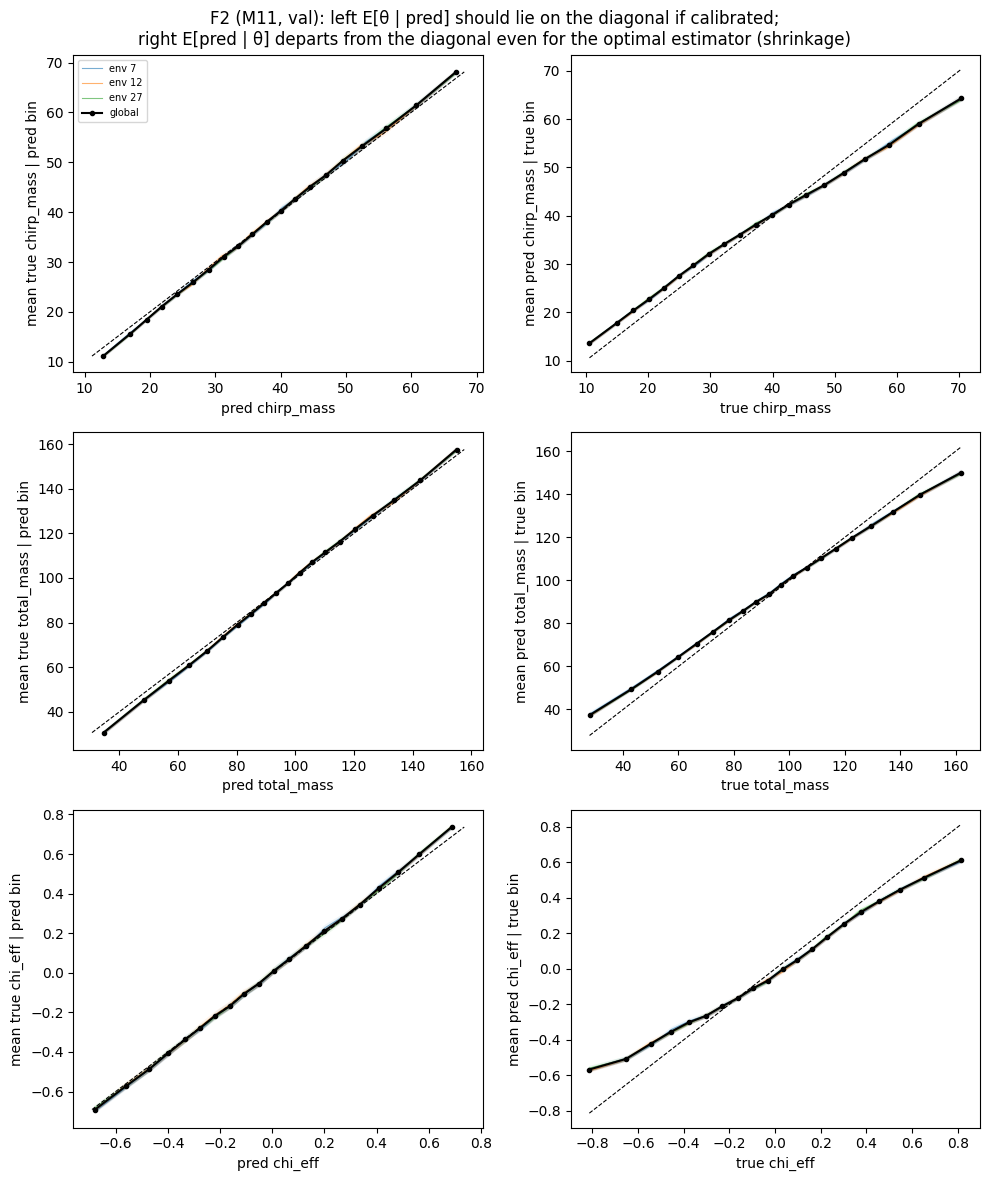

In [12]:
fig, axes = plt.subplots(len(LABELS), 2, figsize=(10, 4 * len(LABELS)))
for j, lab in enumerate(LABELS):
    calib_panel(axes[j, 0], f[:, j], y[:, j], f'pred {lab}', f'mean true {lab} | pred bin')
    calib_panel(axes[j, 1], y[:, j], f[:, j], f'true {lab}', f'mean pred {lab} | true bin')
axes[0, 0].legend(fontsize=7)
fig.suptitle('F2 (M11, val): left E[θ | pred] should lie on the diagonal if calibrated;\n'
             'right E[pred | θ] departs from the diagonal even for the optimal estimator (shrinkage)')
fig.tight_layout()
plt.show()

## 4. F3 — Pendientes frente a R²
Pendiente OLS de la predicción sobre la verdad frente a R² = 1 − SSE/SST para M11 y cada corrector (círculo grande = global, cruz = entorno); para un estimador calibrado, pendiente ≈ R² (recta y = x).

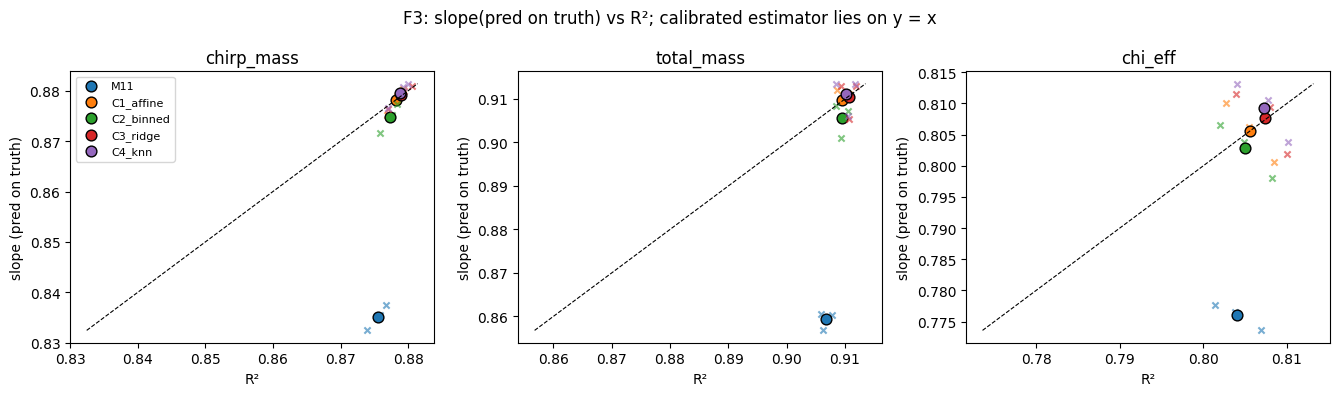

In [13]:
models = ['M11'] + CORRECTORS
colors = dict(zip(models, plt.rcParams['axes.prop_cycle'].by_key()['color']))
fig, axes = plt.subplots(1, len(LABELS), figsize=(4.5 * len(LABELS), 4))
for ax, lab in zip(axes, LABELS):
    s = slopes[slopes.label == lab]
    for mdl in models:
        g = s[(s.model == mdl) & (s.region_type == 'global')]
        e = s[(s.model == mdl) & (s.region_type == 'environment')]
        ax.scatter(e.r2, e.slope_pred_on_truth, marker='x', s=20, color=colors[mdl], alpha=0.6)
        ax.scatter(g.r2, g.slope_pred_on_truth, marker='o', s=60, color=colors[mdl], label=mdl,
                   edgecolor='k')
    lim = [min(s.r2.min(), s.slope_pred_on_truth.min()), max(s.r2.max(), s.slope_pred_on_truth.max())]
    ax.plot(lim, lim, 'k--', lw=0.8)
    ax.set_xlabel('R²')
    ax.set_ylabel('slope (pred on truth)')
    ax.set_title(lab)
axes[0].legend(fontsize=8)
fig.suptitle('F3: slope(pred on truth) vs R²; calibrated estimator lies on y = x')
fig.tight_layout()
plt.show()

In [14]:
slopes[slopes.region_type == 'global'].pivot(
    index='model', columns='label',
    values=['slope_truth_on_pred', 'intercept_truth_on_pred', 'slope_pred_on_truth', 'r2']
).reindex(models)

slope_truth_on_pred                       intercept_truth_on_pred  \
label                 chi_eff chirp_mass total_mass                 chi_eff   
model                                                                         
M11                  1.037688   1.050805   1.058501                0.005559   
C1_affine            0.999863   0.999958   0.999909               -0.000010   
C2_binned            1.002681   1.002916   1.004113                0.000172   
C3_ridge             0.999618   0.999839   1.000063                0.000008   
C4_knn               0.997663   0.999054   0.999057                0.000989   

                                slope_pred_on_truth                        \
label     chirp_mass total_mass             chi_eff chirp_mass total_mass   
model                                                                       
M11        -1.981374  -5.949567            0.776008   0.835143   0.859322   
C1_affine   0.001856   0.007934            0.805643   0.878219   0.909654   
C2_binned  -0.107390  -0.398499            0.802879   0.874752   0.905699   
C3_ridge    0.014586  -0.000464            0.807640   0.879129   0.910550   
C4_knn      0.062696   0.113591            0.809187   0.879600   0.911112   

                 r2                        
label       chi_eff chirp_mass total_mass  
model                                      
M11        0.804043   0.875498   0.906696  
C1_affine  0.805533   0.878182   0.909570  
C2_binned  0.805025   0.877296   0.909409  
C3_ridge   0.807332   0.878988   0.910608  
C4_knn     0.807286   0.878765   0.910251

In [15]:
slopes[slopes.region_type == 'environment'].pivot_table(
    index=['region', 'model'], columns='label',
    values=['slope_truth_on_pred', 'intercept_truth_on_pred'])

intercept_truth_on_pred                        \
label                            chi_eff chirp_mass total_mass   
region model                                                     
12     C1_affine                0.001801   0.091249   0.256873   
       C2_binned                0.002095  -0.031003  -0.130434   
       C3_ridge                 0.002200   0.099207   0.362052   
       C4_knn                   0.003077   0.156321   0.414029   
       M11                      0.006857  -1.932258  -5.789259   
27     C1_affine               -0.002080  -0.165460   0.528984   
       C2_binned               -0.002099  -0.304834   0.146096   
       C3_ridge                -0.002336  -0.094555   0.565917   
       C4_knn                  -0.001357  -0.108813   0.669368   
       M11                      0.004067  -2.123456  -5.589356   
7      C1_affine                0.000162   0.076360  -0.837005   
       C2_binned                0.000437   0.010767  -1.286605   
       C3_ridge                 0.000067   0.035653  -1.017139   
       C4_knn                   0.001160   0.137821  -0.816821   
       M11                      0.005686  -1.889273  -6.514000   

                 slope_truth_on_pred                        
label                        chi_eff chirp_mass total_mass  
region model                                                
12     C1_affine            0.999065   0.999486   0.999677  
       C2_binned            1.001175   1.002801   1.003717  
       C3_ridge             0.998283   0.999315   0.998708  
       C4_knn               0.996545   0.998335   0.998274  
       M11                  1.036628   1.050694   1.058389  
27     C1_affine            0.991005   1.001824   0.996203  
       C2_binned            0.994400   1.004980   0.999928  
       C3_ridge             0.990803   1.000705   0.996050  
       C4_knn               0.988849   1.000481   0.994514  
       M11                  1.031446   1.052599   1.055851  
7      C1_affine            1.009910   0.998670   1.004490  
       C2_binned            1.012837   1.001074   1.009342  
       C3_ridge             1.010194   0.999592   1.006177  
       C4_knn               1.008003   0.998443   1.005015  
       M11                  1.045186   1.049167   1.061638

## 5. F4 — Regiones (descriptivas)
ΔMSE/MSE_M11 regional (%) por corrector con su intervalo como banda; banda gris = ±1 %; cruces rojas = grupos sparse (n < 200, sin decisión). Sin control de multiplicidad entre regiones.

In [21]:
def plot_regions(region_type_of, order, xlabel, title):
    """region_type_of(label) -> region_type in regions.csv; order = x-axis region order."""
    fig, axes = plt.subplots(1, len(LABELS), figsize=(4.8 * len(LABELS), 3.6))
    pos = np.arange(len(order))
    for ax, lab in zip(axes, LABELS):
        r = regions[(regions.region_type == region_type_of(lab)) & (regions.label == lab)]
        ax.axhspan(-1, 1, color='0.85', zorder=0)
        ax.axhline(0, color='k', lw=0.8)
        for c in CORRECTORS:
            rc = r[r.corrector == c].set_index('region').reindex(order)
            ax.plot(pos, 100 * rc.d_mean / rc.mse_m11, '-o', ms=3, label=c)
            ax.fill_between(pos, 100 * rc.ci_lo / rc.mse_m11, 100 * rc.ci_hi / rc.mse_m11, alpha=0.15)
            sp = (rc['sparse'] if 'sparse' in rc.columns
                else rc['descriptive_label'].eq('SPARSE_NO_DECISION')).astype(str).str.lower().eq('true').values
            ax.plot(pos[sp], (100 * rc.d_mean / rc.mse_m11).values[sp], 'rx', ms=8)
        ax.set_xticks(pos)
        ax.set_xticklabels(order, rotation=45, fontsize=8)
        ax.set_xlabel(xlabel)
        ax.set_ylabel('ΔMSE / MSE_M11 (%)')
        ax.set_title(lab)
    axes[0].legend(fontsize=7)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

F4a: por decil de la predicción de M11 de cada etiqueta, evaluando esa misma etiqueta.

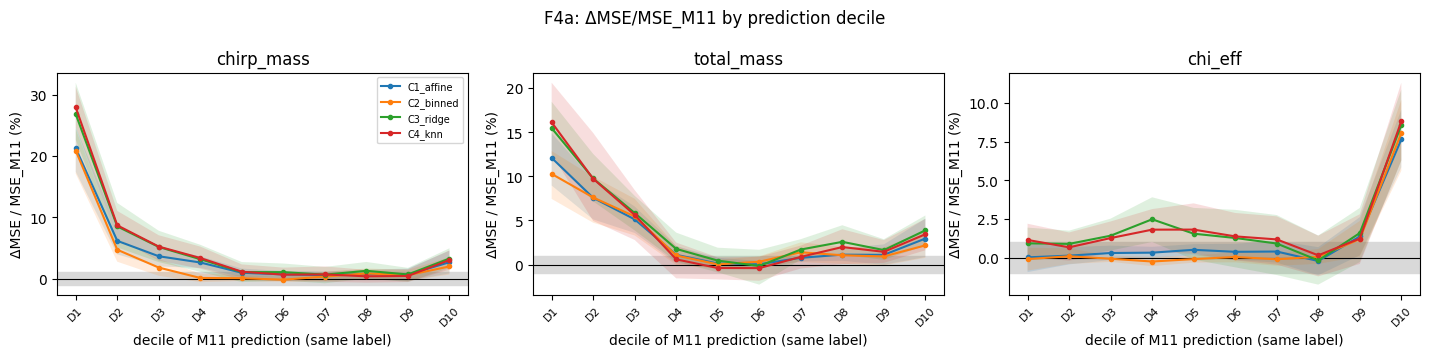

In [22]:
plot_regions(lambda lab: f'pred_decile_{lab}', [f'D{q}' for q in range(1, 11)],
             'decile of M11 prediction (same label)', 'F4a: ΔMSE/MSE_M11 by prediction decile')

F4b: por intervalo de SNR objetivo (solo si el script registró SNR disponible).

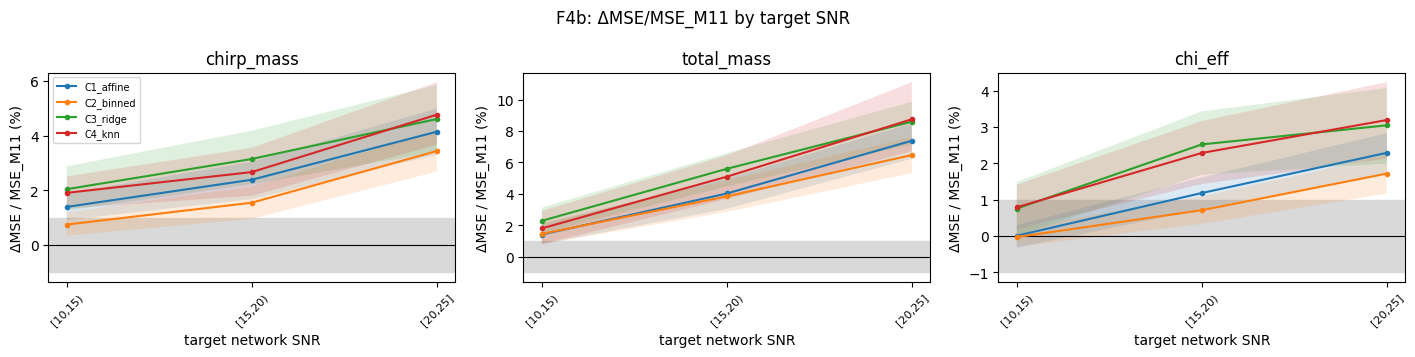

In [23]:
if analysis['snr']['available']:
    snr_order = [f'[{lo:g},{hi:g}' + (']' if closed else ')') for lo, hi, closed in SNR_BINS]
    plot_regions(lambda lab: 'target_snr', snr_order, 'target network SNR',
                 'F4b: ΔMSE/MSE_M11 by target SNR')
else:
    print('SNR not available:', analysis['snr'])

F4c: por entorno de val.

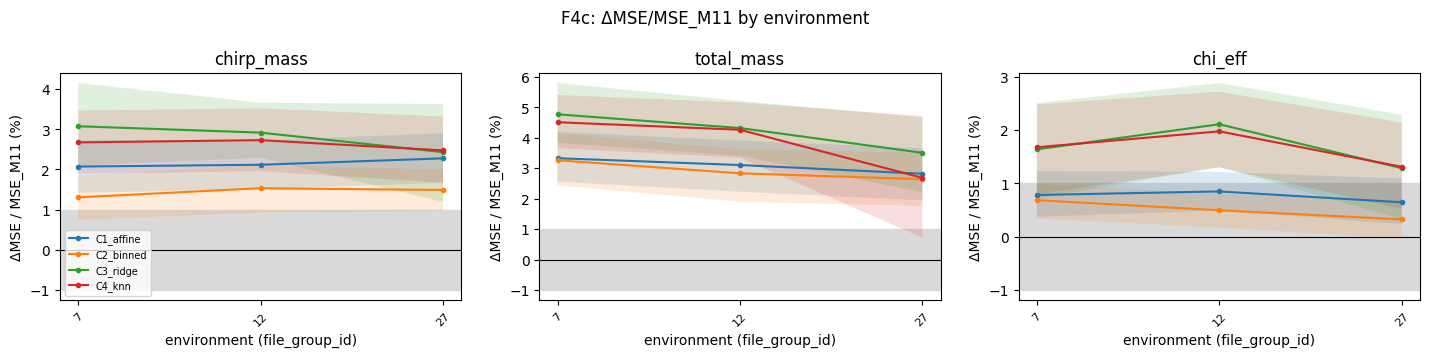

In [24]:
plot_regions(lambda lab: 'environment', ENVS, 'environment (file_group_id)',
             'F4c: ΔMSE/MSE_M11 by environment')

## 6. Hiperparámetros elegidos por fold
Valor elegido por el LOEO interno (C3: α, C4: k) por entorno retenido y etiqueta.

In [26]:
folds[folds.selected].pivot_table(index=['corrector', 'heldout_env'], columns='label',
                                  values='value', aggfunc='first')[LABELS]

label                  chirp_mass  total_mass  chi_eff
corrector heldout_env                                 
C3_ridge  12               1000.0      1000.0    100.0
          27                 10.0       100.0    100.0
          7                 100.0       100.0    100.0
C4_knn    12                256.0       256.0    256.0
          27                256.0        64.0    256.0
          7                 256.0       256.0    256.0

## Conclusiones M12.5.3 — comprobación post-hoc de optimalidad de M11 (val, LOEO por entorno)

**Pregunta.** ¿Cumple M11 la condición necesaria de E[θ|X], E[θ − f | g(X)] = 0, para g construidas con su salida f y su embedding h? Un corrector que reduce el MSE fuera de entorno demuestra riesgo evitable (cota inferior). Que ninguno lo reduzca no demostraría optimalidad.

**Diseño.** C1 afín 3×3 sobre f; C2 calibración por 50 bins de cuantiles de f_j (una etiqueta cada vez); C3 ridge sobre el residuo con [h, f] estandarizados; C4 kNN sobre h. LOEO en los 3 entornos de val (7, 12, 27), hiperparámetros por LOEO interno. Bootstrap pareado intra-entorno (2000, seed 125301), IC 99,58 % (Bonferroni 12), margen 1 % del MSE de M11. npz SHA256 586b95f2…d00ed88b; script c0227440…c77c09; 13/13 checks OK. Deciles de la predicción **con signo** (verificado: el MSE por decil del script coincide con el cálculo con signo y no con |pred|).

**Nota estructural (arquitectura).** En SimpleCNN_ResidualDilated la cabeza es `Linear(64, 3)` aplicada directamente sobre h (el dropout está antes de h) ⇒ f = A·h + a. Por tanto C3 equivale a reajustar la cabeza en val, y C1 a recombinar las 3 direcciones de la cabeza actual. [Pendiente de confirmar numéricamente: lstsq de f sobre h con residuo ≈ 0.]

### Resultados verificados
| ΔMSE/MSE_M11 (%) [IC 99,58 %] | chirp_mass | total_mass | chi_eff |
|---|---|---|---|
| C1 afín | 2,16 [1,81–2,54] ✔ | 3,08 [2,57–3,59] ✔ | 0,76 [0,53–0,99] ✘ |
| C2 bins | 1,44 [1,13–1,76] ✔ | 2,91 [2,41–3,42] ✔ | 0,50 [0,29–0,71] ✘ |
| C3 ridge | **2,80 [2,25–3,46] ✔** | **4,19 [3,57–4,79] ✔** | **1,68 [1,23–2,17] ✔** |
| C4 kNN | 2,62 [2,17–3,12] ✔ | 3,81 [3,01–4,58] ✔ | 1,66 [1,23–2,11] ✔ |

✔ AVOIDABLE_DEMONSTRATED · ✘ NO_EVIDENCE_WITHIN_MARGIN (mejora real pero < 1 %).

1. **M11 no es E[θ|X] en val:** riesgo evitable demostrado de ~2–4 % de MSE (~1–2 % de RMSE) usando solo su propia representación. RMSE de referencia M11 + C3 (fuera de pliegue): 5,745 / 10,373 / 0,1927.
2. **M11 no está calibrado ni linealmente:** pendiente de θ sobre f = 1,051 / 1,059 / 1,038 (chirp / total / χ_eff), con valores 1,031–1,062 en los 3 entornos ⇒ propiedad del estimador, no de un entorno. Las predicciones están comprimidas hacia la media más de lo que justifica la información. Tras corregir: pendiente ≈ 1,000 y ordenada ≈ 0.
3. **La regresión a la media restante es la que corresponde a esta representación:** tras C3, la pendiente de f sobre θ (0,808 / 0,879 / 0,911) coincide con R² (0,807 / 0,879 / 0,911), identidad de un estimador calibrado. Reducirla exige extraer más información de X.
4. **Masas: corrección mayormente lineal** (C1 ≈ 75 % de la ganancia de C3). **χ_eff: la ganancia está en h** (C1 0,8 % → C3/C4 1,7 %). **C4 ≈ C3:** no hay estructura no lineal adicional en h (k = 256, el máximo de la rejilla, en 8/9 pliegues).
5. **La ganancia se concentra en las colas de la predicción** (descriptivo, deciles con signo, ganancia de C3):
   - chirp D1 (pred < 18,3 M☉): 26,9 % del MSE del decil; aporta el **30 %** de la ganancia global con solo el 3 % del MSE global.
   - total D1+D2 (pred < 66,8 M☉): 15,5 % y 9,8 %; aportan el **57 %** de la ganancia global.
   - χ_eff D10 (pred > 0,52): 8,6 %; aporta el **29 %** de la ganancia global. χ_eff D1: 0,9 %. **Asimetría real según el signo.**
   - Por SNR, la ganancia crece con la SNR ([20,25): chirp ~4,5 %, total ~8,5 %, χ_eff ~3 %).
6. **En las colas, la ganancia es casi toda sesgo condicional:** sesgo²/MSE del decil = 22 % (chirp D1), 12 % (total D1), 8 % (χ_eff D10), frente a ganancias de C3 del 27 %, 15 % y 9 %. El sesgo por decil es monótono (chirp −1,55 → +0,95; total −3,53 → +1,90): huella de una salida comprimida. En el centro de χ_eff, la ganancia no viene del sesgo sino de información en h.

### Hipótesis (no verificadas)
- **H1, origen en el entrenamiento:** el dropout antes de h (errores en las variables, la cabeza se ajusta a un h ruidoso), el weight decay 3·10⁻⁴ y/o la parada temprana atenúan la cabeza. Predicción: pendiente > 1 también en train (modo evaluación).
- **H2, cambio de distribución entre los entornos de train y los de val.** Predicción: pendiente ≈ 1 en train.
- **H3, contracción poco adaptativa:** el exceso de contracción es mayor donde hay más información (chirp D1, MSE 10,7 frente a 34 global; χ_eff D10, MSE 0,021 frente a 0,045 en el centro; SNR alta). total_mass D1 encaja peor.
- **Física de χ_eff (asimetría por signo):** los espines alineados con L retrasan la fusión ("orbital hang-up": más ciclos, fusión a más frecuencia) ⇒ χ_eff > 0 mejor medido. Compatible con MSE(D10) < MSE(D1), sin verificar.

### Limitaciones
- Exploratorio: ajustado y evaluado dentro de val (LOEO). cal y test sin tocar. Val se usó además para la parada temprana de M11.
- Solo 3 entornos. El bootstrap no incluye la variabilidad del reajuste del corrector ni la variabilidad entre entornos.
- Regiones sin control de multiplicidad. sesgo²/MSE calculado dentro de val frente a C3 fuera de pliegue: comparación aproximada.
- Ningún resultado demuestra optimalidad. Son cotas inferiores con g = (f, h).

### Consecuencias
- Hay una corrección barata y demostrada (recalibrar o reajustar la cabeza) que ataca justo el sesgo de las colas. No ataca la regresión a la media de fondo, que depende de la información que extrae la red.
- Antes de decidir cómo aplicar esa corrección (con qué datos y si es desplegable), hay que distinguir H1 de H2 (M12.5.4).
- Listón para cualquier modelo nuevo: superar a M11 + C3 bajo el mismo protocolo LOEO, prestando atención a las colas (deciles extremos) y a SNR alta.